# Quantizing a Jet Tagger with Brevitas


In [50]:
# Google Colab setup: uncomment and run this cell once to install every
# dependency used by this notebook, then restart the runtime if prompted.
# Replace workshop_tutorial with the published commit SHA for the participant copy.
#
# # Brevitas (tutorial branch) and the core scientific stack
# !pip install -q git+https://github.com/Xilinx/brevitas.git@workshop_tutorial
# !pip install -q numpy scikit-learn matplotlib
#
# # Export and graph tooling
# !pip install -q 'onnx>=1.15' 'qonnx>=0.5.0' netron
#
# # Optional hls4ml downstream conversion and its model plotter
# !pip install -q hls4ml pydot
# !apt-get -qq install -y graphviz   # provides the `dot` binary that pydot calls


## Brevitas and PyTorch quantization

Brevitas implements simulated quantization with PyTorch modules. PTQ and QAT therefore use familiar parameters, optimizers, and training loops.

The result quant model is still a PyTorch model and quantization is simulated through fake-quantization.

Accelerated execution depends on the export format and the target backend.


## What does it mean to quantize a model?

Quantizing a model requires decisions about tensor roles and boundaries. \
Inputs, weights, biases, activations, outputs, and accumulators require each a specific configuration, although they need not use the same representation.

The examples below use both automated replacement and an explicit model definition. Comparing them makes the selected tensor roles and quantizer recipes visible.

## RTN, PTQ, and QAT

Round-to-nearest (RTN) maps floating-point values to the nearest representable integer under a chosen scale and range. Post-training quantization (PTQ) includes calibration and reconstruction methods such as Qronos. Quantization-aware training (QAT) runs simulated quantization during optimization so model and quantizer parameters can adapt together.

The lab starts with integer RTN and activation calibration. It then moves to minifloat QAT, where scale, exponent width, and mantissa width are trainable.

# Setup and baseline

The separate-presentation version starts here. We assume affine quantization, PTQ, and QAT are familiar and focus on how to express and inspect them in Brevitas.

### Reproducibility

The examples use fixed random seeds, a fixed dataset split, and reported software versions. This keeps differences between model variants attributable to the quantization changes as far as practical. CPU and GPU results may still differ slightly.

The input features are standardized with training-set statistics. They contain both positive and negative values, so the model input requires a signed quantizer.

### Environment and random state

Next we need to import the packages used throughout the notebook, select the available CPU (central processing unit) or GPU (graphics processing unit), and record the software versions used for this run.

In [52]:
from pathlib import Path
import math
import platform
import random

import brevitas
import brevitas.nn as qnn
from importlib.metadata import version
import numpy as np
import sklearn
import torch
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ARTIFACT_DIR = Path('tutorial_artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)

print({
    'python': platform.python_version(),
    'torch': torch.__version__,
    'brevitas': brevitas.__version__,
    'scikit-learn': sklearn.__version__,
    'onnx': version('onnx'),
    'qonnx': version('qonnx'),
    'device': str(DEVICE),
})

{'python': '3.11.14', 'torch': '2.7.1+cu128', 'brevitas': '0.13.4.dev14+gd66b469ee.d20261007', 'scikit-learn': '1.9.0', 'onnx': '1.17.0', 'qonnx': '1.0.0', 'device': 'cuda'}


### Jet-tagging data

First we prepare the data.

Load the OpenML dataset, create a stratified subset, and standardize it with training-set statistics. The same split is used by every model variant.

In [53]:
# OpenML ID 42468: 16 high-level LHC jet features and five jet classes.
dataset = fetch_openml(data_id=42468, as_frame=False)
X = np.asarray(dataset.data, dtype=np.float32)
labels = LabelEncoder().fit_transform(dataset.target)

X_train, X_test, y_train, y_test = train_test_split(
    X, labels, train_size=40_000, test_size=10_000, random_state=SEED, stratify=labels)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long()),
    batch_size=1024, shuffle=True, generator=torch.Generator().manual_seed(SEED))
calibration_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train[:8192]), torch.from_numpy(y_train[:8192]).long()),
    batch_size=1024, shuffle=False)

X_train_t = torch.from_numpy(X_train)
X_test_t = torch.from_numpy(X_test)
y_test_t = torch.from_numpy(y_test).long()
print(f'train={X_train.shape}, test={X_test.shape}, classes={np.unique(labels)}')

train=(40000, 16), test=(10000, 16), classes=[0 1 2 3 4]


### Floating-point baseline

All quantized variants use the same preprocessing and start from these floating-point weights.

The checkpoint is cached in the notebook runtime.

First we define some utility functions that we will re-use throughout the notebook, to train and evaluate the model (either float or quantized):

In [54]:
def evaluate(model):
    model.eval()
    predictions = []
    with torch.no_grad():
        for start in range(0, len(X_test_t), 2048):
            logits = model(X_test_t[start:start + 2048].to(DEVICE))
            predictions.append(logits.argmax(dim=1).cpu())
    return accuracy_score(y_test_t.numpy(), torch.cat(predictions).numpy())


def train_steps(model, loader, optimizer, max_steps, regularizer=None, post_step=None):
    model.train()
    criterion = nn.CrossEntropyLoss()
    losses = []
    for step, (features, targets) in enumerate(loader):
        if step >= max_steps:
            break
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(features), targets)
        if regularizer is not None:
            loss = loss + regularizer(model)
        loss.backward()
        optimizer.step()
        if post_step is not None:
            post_step(model)
        losses.append(loss.detach().item())
    return losses

Afterwards we need to define the model structure, load the checkpoint (or pre-load one if available).\
Notice how the model is a mix of modular (nn.Linear) and functional (torch.relu) calls.

In [55]:
class JetTagger(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 32)
        self.output = nn.Linear(32, 5)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        return self.output(x)


fp32_path = ARTIFACT_DIR / 'jet_tagger_fp32.pt'
fp32_model = JetTagger().to(DEVICE)
if fp32_path.exists():
    fp32_model.load_state_dict(torch.load(fp32_path, map_location=DEVICE, weights_only=True))
else:
    optimizer = torch.optim.Adam(fp32_model.parameters(), lr=3e-3)
    for _ in range(3):
        train_steps(fp32_model, train_loader, optimizer, max_steps=len(train_loader))
    torch.save(fp32_model.state_dict(), fp32_path)

fp32_accuracy = evaluate(fp32_model)
print(f'FP32 accuracy: {fp32_accuracy:.3f}; parameters: {sum(p.numel() for p in fp32_model.parameters()):,}')

fp32_state = {
    name: value.detach().cpu().clone()
    for name, value in fp32_model.state_dict().items()}
example_input_cpu = torch.from_numpy(X_test[:1]).contiguous()

FP32 accuracy: 0.715; parameters: 4,389


### Looking at the network

Before quantizing anything, we draw the floating-point model so we can compare the diagrams of the later variants against it. The renderer walks the module tree and reports each layer's role and numerical format without exporting a graph.

In [56]:
# The workshop ships a small ASCII network renderer next to this notebook.
# On Colab the notebook is opened on its own, so fetch the helper if missing.
from pathlib import Path

if not Path('notebook_utils.py').exists():
    import urllib.request
    url = (
        'https://raw.githubusercontent.com/Xilinx/brevitas/'
        'workshop_tutorial/notebooks/notebook_utils.py')
    urllib.request.urlretrieve(url, 'notebook_utils.py')

from notebook_utils import draw_network

draw_network(fp32_model, title='FP32 jet tagger', orientation='horizontal')

FP32 jet tagger
Input     fc1: Linear 16 -> 64     fc2: Linear 64 -> 32     fc3: Linear 32 -> 32     output: Linear 32 -> 5     Output
      -->   weight: FP32       -->   weight: FP32       -->   weight: FP32       -->   weight: FP32         -->       


# Before we start, a quick recap

First we look at the two objects used throughout the tutorial: a quantizer recipe and a quantized layer. To create a reusable recipe, we subclass the closest predefined quantizer and override only the policy attributes required by the experiment.

In [57]:
from brevitas.core.scaling import ScalingImplType
from brevitas.quant import Int32Bias
from brevitas.quant import Int8ActPerTensorFloat
from brevitas.quant import Int8WeightPerChannelFloat


class Int4WeightPerChannelFloat(Int8WeightPerChannelFloat):
    scaling_impl_type = ScalingImplType.PARAMETER_FROM_STATS # alternatively "parameter_from_stats" would work
    bit_width = 4


for attribute in (
        'bit_width', 'scaling_impl_type', 'scaling_stats_op',
        'scaling_per_output_type', 'float_to_int_impl_type'):
    print(f'{attribute}: {getattr(Int4WeightPerChannelFloat, attribute)}')

bit_width: 4
scaling_impl_type: PARAMETER_FROM_STATS
scaling_stats_op: MAX
scaling_per_output_type: CHANNEL
float_to_int_impl_type: ROUND


### Quantized layer recap

Before converting the model, we need to recall how a quantized layer is assembled. A `QuantLinear` owns separate proxies for its input, weight, bias, and output; each proxy resolves the corresponding quantizer recipe.

In [58]:
recap_linear = qnn.QuantLinear(
    4,
    3,
    input_quant=Int8ActPerTensorFloat,
    weight_quant=Int4WeightPerChannelFloat,
    bias=True,
    bias_quant=Int32Bias,
    return_quant_tensor=True)

for role in ('input_quant', 'weight_quant', 'bias_quant', 'output_quant'):
    proxy = getattr(recap_linear, role)
    if hasattr(proxy, 'tensor_quant'):
        tensor_quant = proxy.tensor_quant
    elif hasattr(proxy, 'fused_activation_quant_proxy'):
        tensor_quant = proxy.fused_activation_quant_proxy.tensor_quant
    else:
        tensor_quant = None
    print(f'{role}: proxy={type(proxy).__name__}, tensor_quant={type(tensor_quant).__name__}')

input_quant: proxy=ActQuantProxyFromInjector, tensor_quant=NoneType
weight_quant: proxy=WeightQuantProxyFromInjector, tensor_quant=RescalingIntQuant
bias_quant: proxy=BiasQuantProxyFromInjector, tensor_quant=PrescaledRestrictIntQuant
output_quant: proxy=ActQuantProxyFromInjector, tensor_quant=NoneType


### QuantTensor recap

We also need to inspect the object exchanged between compatible quantized layers. A `QuantTensor` carries the fake-quantized value together with scale, zero-point, precision, and signedness.

In the next cell we reconstruct the represented value and check that the same object reaches a second quantized layer.

In [59]:
from brevitas.quant_tensor import QuantTensor

recap_input = torch.randn(2, 4)
recap_output = recap_linear(recap_input)

print(type(recap_output).__name__)
print('value shape:', tuple(recap_output.value.shape))
print('integer sample:', recap_output.int()[0].cpu())
print('scale:', recap_output.scale.detach().cpu().flatten())
print('zero point:', recap_output.zero_point.detach().cpu().flatten())
print('bit width:', recap_output.bit_width.detach().cpu().flatten())
print('signed:', recap_output.signed)

reconstructed_output = (
    recap_output.int().type_as(recap_output.value) - recap_output.zero_point
) * recap_output.scale
print('maximum reconstruction error:',
      (reconstructed_output - recap_output.value).abs().max().item())

recap_next = qnn.QuantLinear(
    3, 2, weight_quant=Int4WeightPerChannelFloat, bias=False)
captured_input = {}

def capture_recap_input(module, args):
    captured_input['value'] = args[0]

hook = recap_next.register_forward_pre_hook(capture_recap_input)
recap_next(recap_output)
hook.remove()
print('next layer receives QuantTensor:',
      isinstance(captured_input['value'], QuantTensor))

IntQuantTensor
value shape: (2, 3)
integer sample: tensor([ 175,  136, -298], dtype=torch.int32)
scale: tensor([0.0008, 0.0011, 0.0011])
zero point: tensor([0.])
bit width: tensor([33.])
signed: True
maximum reconstruction error: 5.960464477539063e-08
next layer receives QuantTensor: True


/home/giuseppe/Documents/git/working_brevitas/.venv/lib/python3.11/site-packages/brevitas/quant_tensor/int_torch_handler.py:210: UserWarning: Could not compute output scale factor, returning Tensor
  warnings.warn("Could not compute output scale factor, returning Tensor")


As we can see, the integer representation and its metadata reconstruct the fake-quantized output up to numerical tolerance. The hook also confirms that the second layer receives the complete `QuantTensor`.

### How to apply quantization in Brevitas

Brevitas offers multiple ways to convert a floating point model into a quantized version.

Each mode has its own pros and cons, and we recommend choosing the easiest approach that allows to meet all the necessary requirements in terms of:
- Performance
- Accuracy
- Compatibility with the export flow/compiler toolchain

In the following table we report the four modes currently supported with a brief description to help in the decision process.


| Approach | What it changes | Main advantage | Main limitation |
| --- | --- | --- | --- |
| Layerwise quantization | Replaces supported module instances | Simple mapping and automatic state-dict preservation | Functional calls are not replaced |
| FX-based quantization | Rewrites modules and operations visible in a traced graph | Can place quantization boundaries at graph level | Requires a traceable model |
| Functional quantization (experimental) | Intercepts selected PyTorch operations at runtime | Can reach functional operators without redefining the model | More difficult to configure and not yet suited to every use case |
| Full-model replacement | Defines the quantized model explicitly | Full control over tensor roles and metadata propagation | Requires maintaining a compatible model hierarchy |



# "Standard" quantization with Brevitas

The first part of this tutorial is focused around the most common useflow:
- Easy quantization process with modular layer replacement
    - This means no necessity to quantize functional calls or residual pathways
- Simple quantizers
    - Either pre-defined or slightly customized (e.g., different bit-width)
- Simple export flow
    - All pre-supported operations that map easily to pre-existing export ops


This section produces three useful states:

```text
quant_model
    -> calibrated integer model
    -> Qronos PTQ checkpoint
    -> Qronos + QAT checkpoint
    -> integer QONNX export
```



## Layerwise Quantization


`layerwise_quantize` replaces supported modules in an existing model.\
The function requires a mapping that defines how each layer is mapped to each quantized counterparts, and the quantization configuration for each layer type.

The main advantages are that the state dict is automatically preserved during the conversion, and it requires a simple mapping between float and quant layers.


The mapping requires to specify how to quantize the different elements present inside a QuantLayer.\
The quantization arguments can be as simple as Brevitas' quantizers, but also a lambda function that takes as input the module and returns a quantizer based on the module's characteristics. 

In [60]:
from brevitas.graph.quantize import layerwise_quantize
from brevitas.core.scaling import ScalingImplType
from brevitas.quant import Int32Bias
from brevitas.quant import Int8ActPerTensorFloat
from brevitas.quant import Int8WeightPerChannelFloat


class Int8WeightPerChannelFloat(Int8WeightPerChannelFloat):
    scaling_impl_type = ScalingImplType.PARAMETER_FROM_STATS # alternatively "parameter_from_stats" would work

class Int4WeightPerChannelFloat(Int8WeightPerChannelFloat):
    scaling_impl_type = ScalingImplType.PARAMETER_FROM_STATS # alternatively "parameter_from_stats" would work
    bit_width = 4

class Int8ActPerTensorFloatNewPercentile(Int8ActPerTensorFloat):
    high_percentile_q = 99.0

class Int4ActPerTensorFloatNewPercentile(Int8ActPerTensorFloat):
    bit_width = 4
    high_percentile_q = 99.0

linear_compute_layer_map = {
    nn.Linear: (
        qnn.QuantLinear,
        {
            'input_quant': lambda module: Int8ActPerTensorFloatNewPercentile if module.out_features == 5 else Int4ActPerTensorFloatNewPercentile,
            'weight_quant': lambda module: Int8WeightPerChannelFloat if module.out_features == 5 else Int4WeightPerChannelFloat,
            'bias_quant': Int32Bias,
            'return_quant_tensor': False,
        },
    ),
}
replacement_class, linear_quantizers = linear_compute_layer_map[nn.Linear]
print('Default nn.Linear replacement:', replacement_class.__name__)
for role in ('input_quant', 'weight_quant', 'bias_quant'):
    print(f'  {role}: {linear_quantizers[role].__name__}')
print('  return_quant_tensor:', linear_quantizers['return_quant_tensor'])

Default nn.Linear replacement: QuantLinear
  input_quant: <lambda>
  weight_quant: <lambda>
  bias_quant: Int32Bias
  return_quant_tensor: False


Once the layerwise replacement has been applied, we can inspect the new model.

In particular, we check that the hidden layers use eight-bit weights, the output layer uses four-bit weights, and the original floating-point parameters are preserved. The compact diagram below summarizes the converted layers and their weight and activation formats.

In [61]:
quant_model = JetTagger().to(DEVICE)
quant_model.load_state_dict(fp32_state)
quant_model = layerwise_quantize(
    quant_model, compute_layer_map=linear_compute_layer_map).to(DEVICE)



In [62]:
draw_network(quant_model, title='Layerwise integer jet tagger', mode='compact', orientation='horizontal')

Layerwise integer jet tagger
          fc1: QuantLinear 16 -> 64              fc2: QuantLinear 64 -> 32              fc3: QuantLinear 32 -> 32              output: QuantLinear 32 -> 5                  
Input -->   input: INT4, per-tensor          -->   input: INT4, per-tensor          -->   input: INT4, per-tensor          -->   input: INT8, per-tensor          --> Output
            weight: INT4, per-output-channel       weight: INT4, per-output-channel       weight: INT4, per-output-channel       weight: INT8, per-output-channel           


As we can see, the layerwise map has preserved the dense parameters and applied the requested weight precisions.

The functional `torch.relu` calls are still executed in floating point. Their outputs are quantized when they enter the following `QuantLinear`. We will return to this limitation in the special-cases section.

## Calibration and post-training quantization

A quantizer needs parameters such as scale and, for asymmetric schemes, zero-point. These values can be fixed, computed from statistics, initialized from statistics and stored as parameters, or learned directly.

In this example, both weight quantizers initialize one scale per output channel from maximum weight statistics and then stores those values as parameters.\
Other options, like computing the scale at runtime using different stats ops are pre-implemented. Alternatively it is also possible to define a custom operations.



In [63]:
weight_scaling = quant_model.fc1.weight_quant.tensor_quant.scaling_impl
print('init_done before quant_weight():', bool(weight_scaling.init_done))

weight_qt = quant_model.fc1.quant_weight()
print('init_done after quant_weight():', bool(weight_scaling.init_done))

reconstructed = (weight_qt.int() - weight_qt.zero_point) * weight_qt.scale
print('weight scale shape:', tuple(weight_qt.scale.shape))
print('weight bit width:', weight_qt.bit_width.item())
print('max FP32-to-quantized weight error:', (quant_model.fc1.weight - weight_qt.value).abs().max().item())
print('accuracy before explicit calibration:', evaluate(quant_model))

init_done before quant_weight(): True
init_done after quant_weight(): True
weight scale shape: (64, 1)
weight bit width: 4.0
max FP32-to-quantized weight error: 0.03797680139541626
accuracy before explicit calibration: 0.6458


### Activation calibration

Activations do not have an associated persistent tensor. Their statistics have to be collected from representative inputs. The activation quantizers used here convert those runtime statistics into scale parameters during calibration.

One possibility to define activation scales is to use `calibration_mode`.
The idea is to track statistics across a set of representative data, while we keep quantization disabled, and then set the scale appropriately.

There is no loss, backward pass, or optimizer step. The state snapshots check that quantizer state changes while dense weights and biases remain unchanged.

Importantly the newly set scale (and potentially zero point) are subsequently converted to parameters, which means that they could still be adjusted by gradient descendent later in the process.

In [64]:
from brevitas.graph.calibrate import calibration_mode

# First we observe the scale before calibration
quant_model.eval()
calibration_sample = X_train_t[:256].to(DEVICE)

with torch.no_grad():
    output_before_calibration = quant_model(calibration_sample).detach().cpu()
    input_scale_before = quant_model.fc1.input_quant(calibration_sample).scale.detach().cpu().clone()
state_before_calibration = {
    name: value.detach().cpu().clone() for name, value in quant_model.state_dict().items()}
parameters_before_calibration = {
    name: value.detach().cpu().clone() for name, value in quant_model.named_parameters()}


# This is all it takes to calibrate your model:
# enter the context manager and call the forward pass for as many samples as you need
with torch.no_grad(), calibration_mode(quant_model):
    for features, _ in calibration_loader:
        quant_model(features.to(DEVICE))

Calibration has now collected the activation statistics. We can compare the saved state and verify that quantizer state changed while the dense parameters remained unchanged.

In [65]:
state_after_calibration = quant_model.state_dict()
changed_state = [
    name for name, value in state_after_calibration.items()
    if name not in state_before_calibration
    or not torch.equal(state_before_calibration[name], value.detach().cpu())]
changed_parameters = [
    name for name, value in quant_model.named_parameters()
    if not torch.equal(parameters_before_calibration[name], value.detach().cpu())]

The state comparison has separated quantizer changes from dense parameters. We can now compare the input scale and model output before and after calibration, and evaluate the calibrated model.

In [66]:
with torch.no_grad():
    output_after_calibration = quant_model(calibration_sample).detach().cpu()
    input_scale_after = quant_model.fc1.input_quant(calibration_sample).scale.detach().cpu().clone()
torch.save(
    quant_model.state_dict(), ARTIFACT_DIR / 'jet_tagger_integer_calibrated.pt')
print('state entries changed by calibration:')
for name in changed_state:
    print(' ', name)
# print('dense parameters changed:', changed_dense_parameters)
# print('quantizer parameters initialized from statistics:', changed_quantizer_parameters)
print('input scale before calibration:', input_scale_before.flatten())
print('input scale after calibration:', input_scale_after.flatten())
print('maximum output change:', (output_after_calibration - output_before_calibration).abs().max().item())


state entries changed by calibration:
  fc1.input_quant.fused_activation_quant_proxy.tensor_quant.scaling_impl.value
  fc2.input_quant.fused_activation_quant_proxy.tensor_quant.scaling_impl.value
  fc3.input_quant.fused_activation_quant_proxy.tensor_quant.scaling_impl.value
  output.input_quant.fused_activation_quant_proxy.tensor_quant.scaling_impl.value
input scale before calibration: tensor([0.1250])
input scale after calibration: tensor([0.3376])
maximum output change: 10.906353950500488


Finally we check the accuracy of the calibrated model:

In [67]:
ptq_accuracy = evaluate(quant_model)
print(f'calibrated PTQ accuracy: {ptq_accuracy:.3f}')

calibrated PTQ accuracy: 0.701



As we saw, calibration does not use labels, but the input sample still needs to cover the activation ranges seen at inference.

Adding more data can be beneficial but only up to a point; final accuracy might depend on:
- Quantization configuration
- Out-of-distribution data during evaluation vs training
- Not enough samples
- ...


### Post-training quantization algorithms: Qronos
Although Brevitas was designed with QAT in mind, recently it has evolved to have first-class support for all the latest PTQ algorithms.

One of these is definitely Qronos, an improvement over the popular GPTQ algorithm for greedy layer-wise error correction.

Before continuing, we define two small helpers for the parameter snapshots used by Qronos and QAT. The calibration loops remain explicit in both workflows.

In [68]:
from notebook_utils import snapshot_parameters
from notebook_utils import changed_parameter_names

The calibrated fixed-format `quant_model` can now be refined with Qronos [6]. We save the Qronos checkpoint before continuing QAT on the same model.

Qronos allows to improve accuracy by correcting for quantization error one layer at the time,
while also accounting for the error coming from previous layers in the network.

Because of this, it requires N passes over the calibration set, where N is the total number of quantized layers in your network.

In [69]:
from functools import partial
from brevitas.graph.gpfq import gpfq_mode
from brevitas.graph.qronos import Qronos
from brevitas.graph.utils import remove_weight_orig

qronos_before = snapshot_parameters(quant_model)
qronos_accuracy_before = evaluate(quant_model)

with torch.no_grad(), gpfq_mode(
        model=quant_model,
        algorithm_impl=partial(Qronos, alpha=1e-6),
        create_weight_orig=True,
        use_quant_activations=False,
        act_order=True,
        device='same') as qronos:
    for _ in range(qronos.num_layers):
        for features, _ in calibration_loader:
            qronos.model(features.to(DEVICE))
        qronos.update()

qronos_changed = changed_parameter_names(qronos_before, quant_model)

print('Qronos changed parameters:', qronos_changed)
print('accuracy before Qronos:', qronos_accuracy_before)
print('accuracy after Qronos:', evaluate(quant_model))

# We try as hard as we can to make non-destructive changes.
# In algorithms like GPTQ and Qronos, this means storing one extra tensor
# with the original floating point weights.
# If we don't need them, this help allows to remove them and save memory.
remove_weight_orig(quant_model)
torch.save(
    quant_model.state_dict(), ARTIFACT_DIR / 'jet_tagger_integer_qronos.pt')

Qronos changed parameters: ['fc1.weight', 'fc2.weight', 'fc3.weight', 'output.weight']
accuracy before Qronos: 0.7005
accuracy after Qronos: 0.7015


As we can see, Qronos has updated the dense weights. We remove the temporary `weight_orig` buffers, save this PTQ stage, and continue with QAT on the same `quant_model`.

### QAT after Qronos

Brevitas does not have a strict distiction between PTQ vs QAT, meaning that the same modules and quantizers can be used seamlessy for either approach of accuracy recovery.

This is immediately evident in the next phase; after applying Qronos, we can simply continue with QAT without any change to our model.

Notably, `quant_model.parameters()` contains both the weights of the model, as well as quantization's parameters like scale factors (and zero-point, in case of asymmetric quantization).

In [70]:
parameter_names = [name for name, _ in quant_model.named_parameters()]
quantizer_parameter_names = [
    name for name in parameter_names if 'quant' in name]
print('total parameters:', len(parameter_names))
print('quantizer parameters optimized alongside the weights:',
      len(quantizer_parameter_names))
for name in quantizer_parameter_names[:3]:
    print(' ', name)

qat_optimizer = torch.optim.Adam(quant_model.parameters(), lr=1e-3)
qat_losses = train_steps(
    quant_model, train_loader, qat_optimizer, max_steps=20)

print('short-QAT accuracy:', evaluate(quant_model))
torch.save(
    quant_model.state_dict(), ARTIFACT_DIR / 'jet_tagger_integer_qat.pt')

total parameters: 16
quantizer parameters optimized alongside the weights: 8
  fc1.input_quant.fused_activation_quant_proxy.tensor_quant.scaling_impl.value
  fc1.weight_quant.tensor_quant.scaling_impl.value
  fc2.input_quant.fused_activation_quant_proxy.tensor_quant.scaling_impl.value
short-QAT accuracy: 0.7077


Once the accuracy-recovery phase is finished, we are ready to export out model.

### Built-in QONNX export

Brevitas offers multiple export paths, including but not limited to:
- ONNX
- QONNX
- torchscript
- vLLM
- GGUF

For this example, we are going to look at the build-in QONNX exporter.

In [71]:
import onnx
from brevitas.export import export_qonnx
from qonnx.core.modelwrapper import ModelWrapper
from qonnx.core.onnx_exec import execute_onnx
from qonnx.transformation.infer_shapes import InferShapes

export_original_device = next(quant_model.parameters()).device
export_was_training = quant_model.training
quant_model.cpu().eval()
integer_qonnx_path = ARTIFACT_DIR / 'jet_tagger_integer_qonnx.onnx'
try:
    export_qonnx(
        quant_model,
        args=example_input_cpu,
        export_path=str(integer_qonnx_path),
        opset_version=14,
        dynamo=False)
    integer_onnx_model = onnx.load(integer_qonnx_path)
    onnx.checker.check_model(integer_onnx_model)
    integer_qonnx_model = ModelWrapper(integer_onnx_model).transform(InferShapes())

    initializer_names = {
        initializer.name for initializer in integer_onnx_model.graph.initializer}
    input_name = next(
        value.name for value in integer_onnx_model.graph.input
        if value.name not in initializer_names)
    output_name = integer_onnx_model.graph.output[0].name
    qonnx_output = execute_onnx(
        integer_qonnx_model, {input_name: example_input_cpu.numpy()})[output_name]
    with torch.no_grad():
        torch_output = quant_model(example_input_cpu).numpy()
    export_max_error = float(abs(torch_output - qonnx_output).max())
    export_tolerance = 1e-4
    print('maximum PyTorch/QONNX difference:', export_max_error)
    if export_max_error > export_tolerance:
        raise RuntimeError(
            f'Export parity exceeded {export_tolerance}: {export_max_error}')
finally:
    quant_model.to(export_original_device)
    quant_model.train(export_was_training)

maximum PyTorch/QONNX difference: 2.384185791015625e-07


In [72]:
# Netron renders the exported QONNX graph. This is the serialized inference
# graph, separate from the PyTorch model drawn by draw_network above.
try:
    import netron
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'netron'], check=True)
    import netron
from IPython.display import IFrame


def show_netron(model_path, port=8080):
    netron.start(str(model_path), address=('localhost', port), browse=False)
    return IFrame(src=f'http://localhost:{port}/', width='100%', height=400)


show_netron(integer_qonnx_path, port=8080)

Serving 'tutorial_artifacts/jet_tagger_integer_qonnx.onnx' at http://localhost:8080


### hls4ml conversion

This cell converts the fixed-integer QONNX artifact into an hls4ml project. It does not run synthesis and is excluded from the timed path.

Before conversion we streamline the graph: the weight and bias `Quant` nodes have only constant inputs, which the hls4ml ONNX frontend cannot parse, so we fold them into pre-quantized initializers while keeping the activation `Quant` nodes.

In [73]:
try:
    import hls4ml
except ModuleNotFoundError as error:
    raise RuntimeError(
        'Install the tutorial-tested hls4ml version before running this optional cell') from error
import qonnx.util.cleanup
from qonnx.transformation.gemm_to_matmul import GemmToMatMul
from qonnx.transformation.fold_constants import FoldConstants
from qonnx.transformation.quant_constant_folding import FoldTransposeIntoQuantInit
from qonnx.transformation.general import GiveUniqueNodeNames
from qonnx.transformation.general import RemoveUnusedTensors

hls_qonnx_path = ARTIFACT_DIR / 'jet_tagger_integer_hls4ml.onnx'
qonnx.util.cleanup.cleanup(str(integer_qonnx_path), out_file=str(hls_qonnx_path))
hls_source_model = ModelWrapper(str(hls_qonnx_path))
hls_source_model = hls_source_model.transform(GemmToMatMul())

# The weight and bias Quant nodes have only constant inputs, so they reach the
# hls4ml frontend as nodes without a produced input and break precision
# inference. We fold these constant-only Quant nodes into pre-quantized weight
# initializers; the activation Quant nodes keep a dynamic input and remain.
hls_source_model = hls_source_model.transform(FoldTransposeIntoQuantInit())
hls_source_model = hls_source_model.transform(FoldConstants(exclude_op_types=[]))
hls_source_model = hls_source_model.transform(RemoveUnusedTensors())
hls_source_model = hls_source_model.transform(GiveUniqueNodeNames())
hls_source_model = qonnx.util.cleanup.cleanup_model(hls_source_model)
hls_source_model.save(str(hls_qonnx_path))

hls_config = hls4ml.utils.config_from_onnx_model(
    hls_source_model, granularity='name', backend='Vitis')
hls_model = hls4ml.converters.convert_from_onnx_model(
    hls_source_model,
    output_dir=str(ARTIFACT_DIR / 'hls4ml_jet_tagger'),
    backend='Vitis',
    hls_config=hls_config,
    part='xcu200-fsgd2104-2-e')
print('hls4ml project created; compilation and synthesis are optional follow-up steps')

/home/giuseppe/Documents/git/working_brevitas/.venv/lib/python3.11/site-packages/qonnx/transformation/gemm_to_matmul.py:57: UserWarning: The GemmToMatMul transformation only offers explicit support for version 9 of the Gemm node, but the ONNX version of the supplied model is 14. Thus the transformation may fail or return incomplete results.
  warnings.warn(
/home/giuseppe/Documents/git/working_brevitas/.venv/lib/python3.11/site-packages/hls4ml/model/optimizer/passes/move_scales.py:183: UserWarning: Failed to propagate quantization bias down Add node; model probably not suppored.
  warnings.warn('Failed to propagate quantization bias down Add node; model probably not suppored.', stacklevel=1)


Output layers:  ['Add_3']
Input shape: [16]
Topology:
Layer name: Quant_0, layer type: Quant, current shape: [[1, 16]]
Layer name: MatMul_0, layer type: MatMul, current shape: [[1, 16], [16, 64]]
Layer name: Add_0, layer type: Merge, current shape: [[1, 64], [64]]
Layer name: Relu_0, layer type: Activation, current shape: [[1, 64]]
Layer name: Quant_1, layer type: Quant, current shape: [[1, 64]]
Layer name: MatMul_1, layer type: MatMul, current shape: [[1, 64], [64, 32]]
Layer name: Add_1, layer type: Merge, current shape: [[1, 32], [32]]
Layer name: Relu_1, layer type: Activation, current shape: [[1, 32]]
Layer name: Quant_2, layer type: Quant, current shape: [[1, 32]]
Layer name: MatMul_2, layer type: MatMul, current shape: [[1, 32], [32, 32]]
Layer name: Add_2, layer type: Merge, current shape: [[1, 32], [32]]
Layer name: Relu_2, layer type: Activation, current shape: [[1, 32]]
Layer name: Quant_3, layer type: Quant, current shape: [[1, 32]]
Layer name: MatMul_3, layer type: MatMul,

We can draw the HLS model with hls4ml's built-in plotter. This shows the graph that hls4ml actually builds, annotated with the fixed-point precisions it inferred. It is distinct from the Netron view of the QONNX graph and from the PyTorch `draw_network` diagrams.

In [74]:
hls4ml.utils.plot_model(
    hls_model,
    show_shapes=True,
    show_precision=True,
    to_file=None)

Failed to import pydot. You must install pydot and graphviz for `pydotprint` to work.


# Custom quantizers and exploration

When working on novel research ideas, you might want to extend Brevitas with your stuff + flexibility + composability.

For this reason, this part of the tutorial focuses on what you can do to customise Brevitas and make it perfect for your research ideas or deployment targets.

In paricular, in this second part we will revisit some concepts and experiment with:
- Heavily customized quantizers
    - First we inspect the components of a float quantizer, then replace selected components with custom implementations
- More flexible model conversion
    - FX can quantize functional calls, while full-model replacement gives explicit control over every boundary
- Constrained QAT
    - Scale, exponent, and mantissa parameters are optimized together with the model weights
- Custom export flow
    - Custom handlers map the training-time quantizers to the required QONNX representation



## Anatomy of a float quantizer

A float quantizer is assembled from several independent policies:

| Component | Role | Typical reason to replace it |
| --- | --- | --- |
| Base quantizer | Selects the tensor role and float family | Start from the closest supported recipe |
| Scale implementation | Maps tensor range into format range | Use statistics, calibration, or a learned scale |
| Scale granularity | Defines the scale shape | Choose per-tensor, per-channel, or per-group behavior |
| Exponent width | Controls dynamic range | Fix or learn the available range |
| Mantissa width | Controls local precision | Fix or learn the precision |
| Exponent bias | Defines exponent interpretation | Recompute it when exponent width changes |
| Bit-width restriction | Maps continuous widths to valid formats | Apply rounding, bounds, and format budgets |
| Value rounding | Maps values onto the minifloat grid | Change forward rounding or its gradient estimator |
| Clamp and special values | Handles saturation, Inf, and NaN | Match the numerical convention required by the target |
| Export handler | Defines the external representation | Map custom training behavior to export semantics |

The next cells show these pieces in a concrete learned-minifloat weight quantizer. The hierarchy is the useful part to inspect: a quantizer recipe resolves to a proxy, which owns the float-quantization module and its component implementations.

### A predefined float quantizer

We start with a standard Brevitas E4M3 weight quantizer. The class hierarchy shows which policies are inherited, while the module tree shows the objects created for one `QuantLinear` layer.

In [75]:
from brevitas.quant.float_quant_ocp import Fp8e4m3OCPWeightPerChannelFloat


standard_float_linear = qnn.QuantLinear(
    16, 8, weight_quant=Fp8e4m3OCPWeightPerChannelFloat, bias=False)

print('Quantizer recipe:', Fp8e4m3OCPWeightPerChannelFloat.__name__)


float_quant = standard_float_linear.weight_quant.tensor_quant
modules_to_inspect = (
        'stats_impl',
        'exponent_bit_width_impl', 'mantissa_bit_width_impl',
        'exponent_bias_impl', 'float_to_int_impl', 'float_clamp_impl')
print('Some of the components to inspect or override:')
for name, module in float_quant.named_modules():
    if any([name.endswith(suffix) for suffix in  modules_to_inspect]):
        print(f'  {name}: {type(module).__name__}')

Quantizer recipe: Fp8e4m3OCPWeightPerChannelFloat
Some of the components to inspect or override:
  float_to_int_impl: RoundSte
  exponent_bias_impl: StaticExponentBias
  exponent_bit_width_impl: BitWidthConst
  mantissa_bit_width_impl: BitWidthConst
  scaling_impl.parameter_list_stats.stats.stats_impl: AbsMax
  float_clamp_impl: FloatClamp


A quantizer is composed of many nested classes (try printing `standard_float_linear.weight_quant` and see!).
Given the nested modular structure, it might be tricky to modify high-level components that incorporates mnay sublcasses.

Neverthless, there are plenty of possibility to customise the quantizers to make them fit to your need, even by replacing entire hierarchy of classes.


For example, the rounding class maps the scaled floating-point value to a representable value on the minifloat grid. `float_to_int_impl` controls this operation.

The scale path has more than one part. `stats_impl` computes statistics such as an absolute maximum from the tensor;\
`scaling_impl` turns those statistics into the external scale (e.g., combining it with the threshold);\
`float_scaling_impl` accounts for the range of the selected float format.

The exponent and mantissa width implementations, exponent bias, and clamp determine the remaining format behavior.


### Custom tensor-value rounding

First we start by replacing the module used to round tensor values.
We implement RDFS (the Fourier-based gradient estimator for rounding) from StableQAT [4], replacing the default implementation of straight-through rounding.\
The idea is to have a function where the forward pass still uses `torch.round`, but the backward gradient has a smoother profile.

Let's visualize the difference between the two implementations:



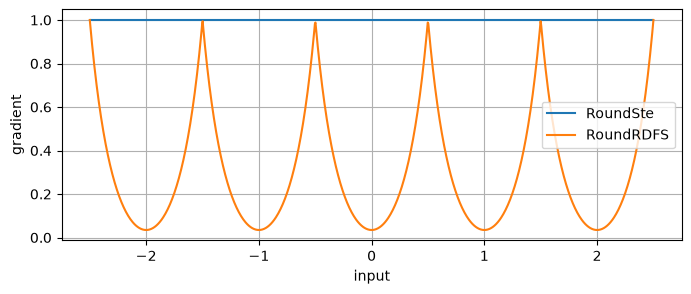

same rounded forward values: True
RoundSte gradient: [1.0, 1.0, 1.0, 1.0]
RoundRDFS gradient: [0.552416205406189, 0.13971984386444092, 0.13971984386444092, 0.552416205406189]


In [76]:
import math
from brevitas.core.function_wrapper import RoundSte
from notebook_utils import plot_rounding_gradients


# Define a new autograd function
class RoundRDFSFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return torch.round(x)

    @staticmethod
    def backward(ctx, grad_output):
        x, = ctx.saved_tensors
        coefficient = 0.21 * math.sqrt(2.) * math.pi
        phase = (x + x.round()) * math.pi
        gradient_estimate = 2. / (1. + coefficient * torch.cos(phase)) - 1.
        return grad_output * gradient_estimate


# Interface around the new autograd function to avoid having to call `.apply`
class RoundRDFS(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return RoundRDFSFunction.apply(x)


plot_rounding_gradients({'RoundSte': RoundSte(), 'RoundRDFS': RoundRDFS()})

## Parameterized minifloat formats

Next we need to replace the constant exponent and mantissa bit-widths with learned parameters. 

We are going to implement:
- per-tensor learned bit-width for activations
- per-channel learned bit-width for weights

Although learned parameters are supported out of the box, Brevitas assumes they are per-tensor parameters, so we need to extend the class to support per-channel granularity.

Afterwards, we re-define the quantizers, starting from some Brevitas' defined templates, and selective add all the new components.
We also use `ComputeExponentBias`, so that the exponent bias is computed with the runtime exponent bit-width value during forward passes.


### Custom activation quantizer

Activation formats use one exponent and mantissa pair per tensor. These injector classes select parameter-backed widths and constrain their legal ranges.

Exponent and Mantissa bit-widths need their own class to avoid name-clash during dependency injection.
Internally we correctly wire each variable to the correct class.

In the case of integer bit-width, we don't need separate container classes since we only have one bit-width parameter.

In [77]:
from dependencies import this
from dependencies import value
from brevitas.core.bit_width import BitWidthImplType
from brevitas.core.bit_width import BitWidthParameter
from brevitas.core.bit_width.float import ComputeExponentBias
from brevitas.core.restrict_val import IntRestrictValue
from brevitas.core.restrict_val import RestrictValueType
from brevitas.core.scaling import ScalingImplType
from brevitas.quant.float import Fp8e4m3ActPerTensorFloat
from brevitas.quant.float import Fp8e4m3WeightPerChannelFloat
from brevitas.quant.solver.common import ExponentBitWidthClass
from brevitas.quant.solver.common import MantissaBitWidthClass

In [78]:

# Dependency Injection works by relying on non-clashing names
# With minifloat quantation, we need separate classes for Mantissa and Exponent to avoid name-clashes (min_bit-width, etc.)

class LearnedExponent(ExponentBitWidthClass):
    # Round learned widths to discrete values in forward; we'll inspect the effect below.
    restrict_bit_width_impl = IntRestrictValue
    min_bit_width = 0
    bit_width_offset_min_val = 1
    bit_width_offset_max_val = 4


class LearnedMantissa(MantissaBitWidthClass):
    restrict_bit_width_impl = IntRestrictValue
    min_bit_width = 0
    bit_width_offset_min_val = 1
    bit_width_offset_max_val = 3

# Inside the main quantizer we reference our containers,
# and then the quantizer will automatically wire each argument to the correct bit-width type

class LearnedMinifloatAct(Fp8e4m3ActPerTensorFloat):
    restrict_scaling_type = RestrictValueType.LOG_FP
    exponent_bit_width_impl_type = BitWidthImplType.PARAMETER
    mantissa_bit_width_impl_type = BitWidthImplType.PARAMETER
    exponent_bit_width = 3
    mantissa_bit_width = 2
    exponent_bit_class = LearnedExponent
    mantissa_bit_class = LearnedMantissa
    exponent_bias_impl = ComputeExponentBias
    float_to_int_impl = RoundRDFS


### Per-Channel bit-width parameter module

First, we define a new class that allows for per-channel bit-widths.
This class requires `bit_width_shape`, which is resolved through dependency injection.


In [79]:

class PerChannelBitWidthParameter(BitWidthParameter):
    def __init__(
            self, bit_width, bit_width_shape,
            bit_width_offset_min_val, bit_width_offset_max_val,
            dtype=None, device=None):
        super().__init__(
            bit_width=bit_width,
            min_bit_width=0,
            bit_width_offset_min_val=bit_width_offset_min_val,
            bit_width_offset_max_val=bit_width_offset_max_val,
            dtype=dtype,
            device=device)
        initial_value = self.bit_width_offset.detach().expand(bit_width_shape).clone()
        self.bit_width_offset = nn.Parameter(initial_value)




### Custom weight quantizer

The weight recipe starts from the predefined per-channel E4M3 quantizer. We replace scale initialization, E/M implementations, exponent bias, and value rounding while leaving the existing proxy and float-quantization core unchanged.

The shape arguments used below are injected from the parent weight module: `weight_ndims` is the rank of its weight tensor, `output_channel_dim` identifies the output-channel axis, and `out_channels` gives its size.

In [80]:
# These classes are similar to before, although we need to fetch one attribute from the main quantizer class, bit_width_shape.
# The Exponent and Mantissa classes are isolated containers. 
# They can define new variables that won't name-clash with other similar classes,
# however they cannot transparently access all the variables defined by the LearnedMinifloatWeight, the main quantizer class.

# To access a variable defined in the main quantizer, we need to use "(this << 1)", which translates to
# "look up one level for the variable with that name".


class LearnedPerChannelExponent(ExponentBitWidthClass):
    restrict_bit_width_impl = IntRestrictValue
    bit_width_shape = (this << 1).bit_width_shape
    bit_width_impl_type = PerChannelBitWidthParameter
    bit_width_offset_min_val = 1
    bit_width_offset_max_val = 4


class LearnedPerChannelMantissa(MantissaBitWidthClass):
    restrict_bit_width_impl = IntRestrictValue
    bit_width_shape = (this << 1).bit_width_shape
    bit_width_impl_type = PerChannelBitWidthParameter
    bit_width_offset_min_val = 1
    bit_width_offset_max_val = 3

from notebook_utils import where_defined

# weight_ndims, output_channel_dim, out_channels are all defined within "Fp8e4m3WeightPerChannelFloat"
class LearnedMinifloatWeight(Fp8e4m3WeightPerChannelFloat):
    """
    Since we are inheriting from Fp8e4m3WeightPerChannelFloat, we can access
    other attributes provided by the class, like weight_ndims, output_channel_dim, etc.
    """
    @value
    def bit_width_shape(weight_ndims, output_channel_dim, out_channels):
        shape = [1] * weight_ndims
        shape[output_channel_dim] = out_channels
        return tuple(shape)

    scaling_impl_type = ScalingImplType.PARAMETER_FROM_STATS
    restrict_scaling_type = RestrictValueType.LOG_FP
    exponent_bit_width_impl_type = BitWidthImplType.PARAMETER
    mantissa_bit_width_impl_type = BitWidthImplType.PARAMETER
    exponent_bit_width = 3
    mantissa_bit_width = 2
    exponent_bit_class = LearnedPerChannelExponent
    mantissa_bit_class = LearnedPerChannelMantissa
    exponent_bias_impl = ComputeExponentBias
    float_to_int_impl = RoundRDFS


# where_defined walks the quantizer class hierarchy and reports which class
# defines an attribute, along with its source file.
where_defined(LearnedMinifloatWeight, 'float_to_int_impl')
where_defined(LearnedMinifloatWeight, 'exponent_bias_impl')

float_to_int_impl: not found in LearnedMinifloatWeight hierarchy
exponent_bias_impl: not found in LearnedMinifloatWeight hierarchy


### Custom quantizer inspection

The activation recipe keeps one E/M pair per tensor. It reuses the scalar width classes and the same RDFS rounding module.

In [81]:
for quantizer in (LearnedMinifloatWeight, LearnedMinifloatAct):
    print(quantizer.__name__)
    print('  base format: Fp8e4m3')
    print('  scale:', quantizer.scaling_impl_type)
    print('  exponent:', quantizer.exponent_bit_width_impl_type)
    print('  mantissa:', quantizer.mantissa_bit_width_impl_type)
    print('  value rounding:', quantizer.float_to_int_impl)

LearnedMinifloatWeight
  base format: Fp8e4m3
  scale: PARAMETER_FROM_STATS
  exponent: PARAMETER
  mantissa: PARAMETER
  value rounding: RoundRDFS()
LearnedMinifloatAct
  base format: Fp8e4m3
  scale: parameter_from_stats
  exponent: PARAMETER
  mantissa: PARAMETER
  value rounding: RoundRDFS()


The standard recipe gives us the complete layer/proxy/float-quantization stack. The custom recipe below keeps that stack and replaces selected policies:

| Component | Standard E4M3 recipe | Learned recipe |
| --- | --- | --- |
| Scale | Predefined per-channel scale | Parameter-from-statistics, log-restricted scale |
| Exponent width | Constant | Learned per output channel |
| Mantissa width | Constant | Learned per output channel |
| Exponent bias | Static/default | Recomputed from the learned exponent |
| Value rounding | Standard rounding | RDFS module |
| Export | Built-in handler | Custom handler for learned metadata |

The learned-minifloat recipes reuse the scaled-minifloat implementation and override only the scale, width, exponent-bias, and rounding policies required for this experiment.

More importantly, considering how all the various elements interact between them, it means that standalone modules like the new rounding function can be easily combined with different types of quantizers.\
A similar experiment with integer quantization would require just re-defining a new quantizer using the `RoundRDFS` class for `float_to_int_impl`.

### Full-model replacement

When exact tensor boundaries matter, we can define the same learned-minifloat model explicitly. The dense module names match the FP32 model, so its checkpoint can initialize the new model while the quantizer state is created separately.

In [82]:
from contextlib import contextmanager
import brevitas.config as brevitas_config


@contextmanager
def ignore_missing_quantizer_keys():
    previous_value = brevitas_config.IGNORE_MISSING_KEYS
    brevitas_config.IGNORE_MISSING_KEYS = True
    try:
        yield
    finally:
        brevitas_config.IGNORE_MISSING_KEYS = previous_value


class LearnedMinifloatJetTagger(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_quant = qnn.QuantIdentity(
            act_quant=LearnedMinifloatAct, return_quant_tensor=True)
        self.fc1 = qnn.QuantLinear(16, 64, weight_quant=LearnedMinifloatWeight)
        self.act1 = qnn.QuantReLU(
            act_quant=LearnedMinifloatAct, return_quant_tensor=True)
        self.fc2 = qnn.QuantLinear(64, 32, weight_quant=LearnedMinifloatWeight)
        self.act2 = qnn.QuantReLU(
            act_quant=LearnedMinifloatAct, return_quant_tensor=True)
        self.fc3 = qnn.QuantLinear(32, 32, weight_quant=LearnedMinifloatWeight)
        self.act3 = qnn.QuantReLU(
            act_quant=LearnedMinifloatAct, return_quant_tensor=True)
        self.output = qnn.QuantLinear(32, 5, weight_quant=LearnedMinifloatWeight)

    def forward(self, x):
        x = self.input_quant(x)
        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))
        x = self.act3(self.fc3(x))
        return self.output(x)

The detailed diagram reports the learned `ExMx` format of each quantizer. Activation formats are per-tensor, so they appear as a single line. Weight formats are per-output-channel, so the first channels are shown for each linear layer.

In [83]:
draw_network(
    LearnedMinifloatJetTagger(),
    title='Learned-minifloat jet tagger',
    mode='detailed', orientation='horizontal')

Learned-minifloat jet tagger
          input_quant: QuantIdentity     fc1: QuantLinear 16 -> 64            act1: QuantReLU        fc2: QuantLinear 64 -> 32            act2: QuantReLU        fc3: QuantLinear 32 -> 32            act3: QuantReLU        output: QuantLinear 32 -> 5                
Input -->   activation: E3M2         -->   weights: E3M2, E3M2, E3M2, ... -->   activation: E3M2 -->   weights: E3M2, E3M2, E3M2, ... -->   activation: E3M2 -->   weights: E3M2, E3M2, E3M2, ... -->   activation: E3M2 -->   weights: E3M2, E3M2, E3M2, ... --> Output
                                           rounding: RoundRDFS                                         rounding: RoundRDFS                                         rounding: RoundRDFS                                         rounding: RoundRDFS                      


### Another possibility: FX-based graph replacement

The explicit model above keeps every quantization boundary visible in its source. We can also apply the same minifloat recipes through FX graph conversion, which rewrites the functional ReLUs before inserting the quantized modules.

In [84]:
from brevitas.graph.quantize import preprocess_for_quantize
from brevitas.graph.quantize import quantize

learned_compute_layer_map = {
    nn.Linear: (
        qnn.QuantLinear,
        {'weight_quant': LearnedMinifloatWeight, 'return_quant_tensor': True}),
}
learned_quant_act_map = {
    nn.ReLU: (
        qnn.QuantReLU,
        {'act_quant': LearnedMinifloatAct, 'return_quant_tensor': True}),
}
learned_quant_identity_map = {
    role: (
        qnn.QuantIdentity,
        {'act_quant': LearnedMinifloatAct, 'return_quant_tensor': True})
    for role in ('signed', 'unsigned')
}

fx_source_model = JetTagger().cpu()
fx_source_model.load_state_dict(fp32_state)
fx_preprocessed_model = preprocess_for_quantize(
    fx_source_model, trace_model=True)
fx_quant_model = quantize(
    fx_preprocessed_model,
    quant_identity_map=learned_quant_identity_map,
    compute_layer_map=learned_compute_layer_map,
    quant_act_map=learned_quant_act_map).to(DEVICE)
print('learned-minifloat FX graph:')
print(fx_quant_model.graph)

learned-minifloat FX graph:
graph():
    %x : [#users=1] = placeholder[target=x]
    %x_quant : [#users=1] = call_module[target=x_quant](args = (%x,), kwargs = {})
    %fc1 : [#users=1] = call_module[target=fc1](args = (%x_quant,), kwargs = {})
    %fc1_output_quant : [#users=1] = call_module[target=fc1_output_quant](args = (%fc1,), kwargs = {})
    %relu : [#users=1] = call_function[target=torch.relu](args = (%fc1_output_quant,), kwargs = {})
    %fc2_input_quant : [#users=1] = call_module[target=fc2_input_quant](args = (%relu,), kwargs = {})
    %fc2 : [#users=1] = call_module[target=fc2](args = (%fc2_input_quant,), kwargs = {})
    %fc2_output_quant : [#users=1] = call_module[target=fc2_output_quant](args = (%fc2,), kwargs = {})
    %relu_1 : [#users=1] = call_function[target=torch.relu](args = (%fc2_output_quant,), kwargs = {})
    %fc3_input_quant : [#users=1] = call_module[target=fc3_input_quant](args = (%relu_1,), kwargs = {})
    %fc3 : [#users=1] = call_module[target=fc3](args

The converted graph exposes the ReLUs as modules and applies the learned-minifloat recipes at its input, activation, and linear boundaries. This model demonstrates graph-level conversion and remains isolated from the QAT path below.

### Learned-format QAT

We load the FP32 weights into the explicit learned-minifloat model, calibrate activation scales, and then optimize dense weights, scales, and per-channel E/M parameters together.

Qronos is not used in this path because the representable weight formats can change during QAT. It could be tested after the formats are frozen, but that combination is outside this tutorial.

### Reading learned formats

Before QAT, we need helpers that read the effective E/M values from every weight and activation quantizer. We also define `format_size_cost`, which averages each quantizer's format size including the sign bit.

In [85]:
def learned_formats(model, force_eval=False):
    formats = {}
    for name, module in model.named_modules():
        if isinstance(module, qnn.QuantLinear):
            weight = module.quant_weight()
            formats[f'{name}.weight'] = (
                weight.exponent_bit_width, weight.mantissa_bit_width)
        elif isinstance(module, (qnn.QuantIdentity, qnn.QuantReLU)):
            formats[f'{name}.activation'] = (
                module.act_quant.exponent_bit_width(force_eval=force_eval),
                module.act_quant.mantissa_bit_width(force_eval=force_eval))
    return formats


def format_size_cost(model):
    totals = [
        (1. + exponent + mantissa).float().mean()
        for exponent, mantissa in learned_formats(model).values()]
    return torch.stack(totals).mean()

### Enforcing the format budget

The E/M parameters are optimized as continuous values, so we need to project them after every optimizer step. Exponent is kept within E1-E4; mantissa receives the remaining budget up to M3. We also define a checker for the effective discrete formats.

In [86]:
from brevitas.core.quant.float import FloatQuant


def project_format_budget(model):
    # Preserve exponent range, then give mantissa the remaining format budget.
    with torch.no_grad():
        for module in model.modules():
            if isinstance(module, FloatQuant):
                exponent_impl = module.exponent_bit_width_impl
                mantissa_impl = module.mantissa_bit_width_impl
                exponent_offset = exponent_impl.bit_width_offset
                mantissa_offset = mantissa_impl.bit_width_offset
                if not (torch.isfinite(exponent_offset).all().item()
                        and torch.isfinite(mantissa_offset).all().item()):
                    raise RuntimeError('Non-finite learned minifloat width')
                exponent_offset.abs_().clamp_(1., 4.)
                max_mantissa = torch.minimum(
                    torch.full_like(exponent_offset, 3.), 7. - exponent_offset)
                mantissa_offset.abs_()
                mantissa_offset.copy_(
                    torch.minimum(mantissa_offset, max_mantissa).clamp_min_(1.))
                effective_sum = exponent_impl() + mantissa_impl()
                if not torch.isfinite(effective_sum).all().item() or not (effective_sum <= 7.).all().item():
                    raise RuntimeError('Format projection failed to enforce E + M <= 7')


def check_format_budget(model):
    checks = []
    for name, (exponent, mantissa) in learned_formats(model, force_eval=True).items():
        exponent = exponent.detach()
        mantissa = mantissa.detach()
        valid = (
            (1. <= exponent) & (exponent <= 4.)
            & (1. <= mantissa) & (mantissa <= 3.)
            & (exponent == exponent.round())
            & (mantissa == mantissa.round())
            & (exponent + mantissa <= 7.)).all().item()
        formats = torch.unique(
            torch.stack((exponent.flatten(), mantissa.flatten()), dim=1), dim=0)
        checks.append(valid)
        print(f'{name}: formats={formats.cpu().tolist()} valid={valid}')
    return all(checks)

### Initializing the learned-format model

We load the FP32 weights into the explicit model and calibrate the activation scales before QAT.

In [87]:
qat_model = LearnedMinifloatJetTagger()
with ignore_missing_quantizer_keys():
    qat_model.load_state_dict(fp32_model.state_dict())
qat_model.eval().to(DEVICE)
with torch.no_grad(), calibration_mode(qat_model):
    for features, _ in calibration_loader:
        qat_model(features.to(DEVICE))

Calibration has initialized the activation quantizer state from representative data.

We can now start QAT. Gradients reach dense weights, scales, and E/M parameters. 

A continuous per-channel E/M parameter can change without crossing a rounding boundary, so its effective format may remain unchanged during this short run. Try adjusting the max_steps in case!

In [88]:
optimizer = torch.optim.Adam(qat_model.parameters(), lr=1e-1)
losses = train_steps(
    qat_model, train_loader, optimizer, max_steps=80,
    regularizer=lambda model: 1e-3 * format_size_cost(model),
    post_step=project_format_budget)


In [89]:
draw_network(
    qat_model,
    title='Learned-minifloat jet tagger',
    mode='detailed', orientation='horizontal')

Learned-minifloat jet tagger
          input_quant: QuantIdentity     fc1: QuantLinear 16 -> 64            act1: QuantReLU        fc2: QuantLinear 64 -> 32            act2: QuantReLU        fc3: QuantLinear 32 -> 32            act3: QuantReLU        output: QuantLinear 32 -> 5                
Input -->   activation: E4M2         -->   weights: E3M3, E3M3, E2M2, ... -->   activation: E4M3 -->   weights: E2M3, E1M2, E1M3, ... -->   activation: E4M2 -->   weights: E1M3, E1M3, E1M1, ... -->   activation: E4M3 -->   weights: E1M2, E1M1, E3M3, ... --> Output
                                           rounding: RoundRDFS                                         rounding: RoundRDFS                                         rounding: RoundRDFS                                         rounding: RoundRDFS                      


The QAT steps have completed. We now need to compare the updated parameters with the pre-QAT snapshot, check the E/M budget, and report the short-run accuracy.

In [90]:
print(f'loss: {losses[0]:.3f} -> {losses[-1]:.3f}')
qat_path = ARTIFACT_DIR / 'jet_tagger_learned_minifloat_qat.pt'
torch.save(qat_model.state_dict(), qat_path)
print('short-QAT accuracy:', evaluate(qat_model))

loss: 0.886 -> 1.337
short-QAT accuracy: 0.4499


### Custom QONNX export

The learned-format model uses a notebook-local rounding component and per-channel E/M metadata. We therefore need custom handlers that define how these values are represented in QONNX.

RDFS changes only the backward pass, so its inference representation is `ROUND`. A component with different forward semantics would also require a new symbolic and backend implementation.

### Exporting learned minifloat metadata

First we need to collect the metadata required by a QONNX `FloatQuant` node. The helper reads the effective E/M format and computes its maximum finite value.

In [ ]:
from brevitas.export.onnx.qonnx.handler import BrevitasActFloatQuantProxyHandler
from brevitas.export.onnx.qonnx.handler import BrevitasWeightFloatQuantProxyHandler
from brevitas.export.onnx.qonnx.manager import QONNXManager
from brevitas.function.ops import compute_max_mantissa
from brevitas.function.ops import max_float


def rdfs_export_metadata(
        scale, exponent_bit_width, mantissa_bit_width, exponent_bias,
        inf_values, nan_values, saturating):
    if not (
            exponent_bit_width.shape == mantissa_bit_width.shape
            == exponent_bias.shape):
        raise RuntimeError('E/M/bias metadata shapes do not match')
    # Reuse Brevitas' own minifloat helpers. They are elementwise tensor ops,
    # so they broadcast over the per-output-channel E/M formats.
    max_mantissa = compute_max_mantissa(mantissa_bit_width)
    max_float_value = max_float(
        exponent_bit_width, max_mantissa, exponent_bias).type_as(scale)
    symbolic_kwargs = {
        'scale': scale,
        'exponent_bit_width': exponent_bit_width,
        'mantissa_bit_width': mantissa_bit_width,
        'exponent_bias': exponent_bias,
        'has_inf': inf_values is not None,
        'has_nan': nan_values is not None,
        'saturating': saturating,
        'has_subnormal': True,
        'rounding_mode': 'ROUND',
        'max_float': max_float_value}
    return_args = {
        'scale': scale,
        'zero_point': torch.zeros_like(scale),
        'exponent_bit_width': exponent_bit_width,
        'mantissa_bit_width': mantissa_bit_width,
        'exponent_bias': exponent_bias,
        'saturating': saturating,
        'inf_values': inf_values,
        'nan_values': nan_values}
    return symbolic_kwargs, return_args

### Weight and activation handlers

Next we define separate handlers for weights and activations. The weight handler reads metadata from the quantized weight, while the activation handler reads it from the activation proxy. Both check that the proxy uses `RoundRDFS`.

In [92]:
def require_rdfs_rounding(module):
    if hasattr(module, 'fused_activation_quant_proxy'):
        rounding_impl = module.fused_activation_quant_proxy.tensor_quant.float_to_int_impl
    else:
        rounding_impl = module.tensor_quant.float_to_int_impl
    if not isinstance(rounding_impl, RoundRDFS):
        raise RuntimeError('TutorialQONNXManager only handles RoundRDFS float proxies')


class RDFSWeightFloatQuantProxyHandler(BrevitasWeightFloatQuantProxyHandler):
    def prepare_for_export(self, module):
        if module.is_quant_enabled:
            require_rdfs_rounding(module)
            quant_weight = module.tracked_module_list[0].quant_weight()
            self.validate(quant_weight.zero_point)
            self.symbolic_kwargs, self.return_args = rdfs_export_metadata(
                quant_weight.scale, quant_weight.exponent_bit_width,
                quant_weight.mantissa_bit_width, quant_weight.exponent_bias,
                quant_weight.inf_values, quant_weight.nan_values,
                quant_weight.saturating)


class RDFSActFloatQuantProxyHandler(BrevitasActFloatQuantProxyHandler):
    def prepare_for_export(self, module):
        if module.is_quant_enabled:
            require_rdfs_rounding(module)
            self.validate(module)
            self.symbolic_kwargs, self.return_args = rdfs_export_metadata(
                module.scale(), module.exponent_bit_width(),
                module.mantissa_bit_width(), module.exponent_bias(),
                module.inf_values(), module.nan_values(), module.is_saturating())




### Registering the handlers

With the handlers defined, we need to register them before the standard QONNX handlers. This ensures that they are selected for the float proxies used by the tutorial model.

In [93]:
class TutorialQONNXManager(QONNXManager):
    # Handler lookup uses the first exact proxy-type match.
    handlers = [
        RDFSWeightFloatQuantProxyHandler,
        RDFSActFloatQuantProxyHandler,
        *QONNXManager.handlers]


print('Custom export mappings:')
print('  RoundRDFS weight forward -> QONNX FloatQuant[ROUND]')
print('  RoundRDFS activation forward -> QONNX FloatQuant[ROUND]')

Custom export mappings:
  RoundRDFS weight forward -> QONNX FloatQuant[ROUND]
  RoundRDFS activation forward -> QONNX FloatQuant[ROUND]


### Exporting the learned model

The export manager is now ready. We check the format budget once more, export the model, and load the resulting ONNX graph.

In [94]:
import onnx
from qonnx.core.modelwrapper import ModelWrapper
from qonnx.transformation.infer_shapes import InferShapes

custom_export_device = next(qat_model.parameters()).device
custom_export_training = qat_model.training
qat_model.cpu().eval()
qonnx_path = ARTIFACT_DIR / 'jet_tagger_learned_minifloat_qonnx.onnx'
example_input = torch.from_numpy(X_test[:1])
try:
    if not check_format_budget(qat_model):
        raise RuntimeError('Refusing to export an invalid learned format')
    TutorialQONNXManager.export(
        qat_model, args=example_input, export_path=str(qonnx_path),
        opset_version=14)
finally:
    qat_model.to(custom_export_device)
    qat_model.train(custom_export_training)

onnx_model = onnx.load(qonnx_path)
onnx.checker.check_model(onnx_model)
qonnx_model = ModelWrapper(onnx_model).transform(InferShapes())

input_quant.activation: formats=[[4.0, 2.0]] valid=True
fc1.weight: formats=[[1.0, 1.0], [1.0, 2.0], [1.0, 3.0], [2.0, 1.0], [2.0, 2.0], [2.0, 3.0], [3.0, 1.0], [3.0, 2.0], [3.0, 3.0]] valid=True
act1.activation: formats=[[4.0, 3.0]] valid=True
fc2.weight: formats=[[1.0, 1.0], [1.0, 2.0], [1.0, 3.0], [2.0, 1.0], [2.0, 2.0], [2.0, 3.0], [3.0, 2.0], [3.0, 3.0]] valid=True
act2.activation: formats=[[4.0, 2.0]] valid=True
fc3.weight: formats=[[1.0, 1.0], [1.0, 2.0], [1.0, 3.0], [2.0, 1.0], [2.0, 2.0], [2.0, 3.0], [3.0, 1.0], [3.0, 2.0]] valid=True
act3.activation: formats=[[4.0, 3.0]] valid=True
output.weight: formats=[[1.0, 1.0], [1.0, 2.0], [1.0, 3.0], [3.0, 1.0], [3.0, 3.0]] valid=True


The exported model has passed `onnx.checker`. We open it in Netron to see the serialized QONNX graph, including the `FloatQuant` nodes. This is the inference graph, which is separate from the PyTorch model structure we drew earlier.

In [97]:
show_netron(qonnx_path, port=8084)

Serving 'tutorial_artifacts/jet_tagger_learned_minifloat_qonnx.onnx' at http://localhost:8084


The graph structure is valid. We redraw the model in detailed mode so the per-channel `ExMx` formats carried into the export are visible next to the Netron graph.

In [ ]:
draw_network(
    qat_model,
    title='Exported learned-minifloat formats',
    mode='detailed',
    orientation='horizontal')

Exported learned-minifloat formats
          input_quant: QuantIdentity     fc1: QuantLinear 16 -> 64            act1: QuantReLU        fc2: QuantLinear 64 -> 32            act2: QuantReLU        fc3: QuantLinear 32 -> 32            act3: QuantReLU        output: QuantLinear 32 -> 5                
Input -->   activation: E4M2         -->   weights: E3M3, E3M3, E2M2, ... -->   activation: E4M3 -->   weights: E2M3, E1M2, E1M3, ... -->   activation: E4M2 -->   weights: E1M3, E1M3, E1M1, ... -->   activation: E4M3 -->   weights: E1M2, E1M1, E3M3, ... --> Output
                                           rounding: RoundRDFS                                         rounding: RoundRDFS                                         rounding: RoundRDFS                                         rounding: RoundRDFS                      


The metadata read-back confirms that the exported graph contains the selected per-channel formats. We do not execute this heterogeneous `FloatQuant` graph here; QONNX backend support for vector-valued format metadata is a separate question.

# Runtime note

The fixed-integer QONNX path above includes the runtime parity check. The learned per-channel minifloat path stops at ONNX validation, graph inspection, and metadata read-back.

As we can see, the graph contains the selected heterogeneous E/M formats and uses `ROUND` for inference.

This graph-only check does not establish runtime support for vector-valued `FloatQuant` metadata. A new forward operation would additionally need a schema, shape inference, reference execution, and backend lowering.

## Ideas for further experiments

The cells in the second part can be edited and rerun. Some useful starting points are:

### Quantizer recipe

- Keep E/M fixed before making them trainable.
- Try a predefined MSE-based scale implementation.
- Change scale granularity or the scale statistics.
- Switch quantizers to integer learned bit-width.

### Format parameters

- Change the initial exponent and mantissa widths.
- Change the E/M bounds or the total format budget.
- Change the per-channel initialization pattern.
- Compare stored continuous values with effective discrete formats.
- Replace the computed exponent bias with a bounded learnable module; update the export metadata to use the learned value

### Rounding

- Replace RDFS with the standard rounding module, or with a different function for forward/backward.

### Model conversion

- Change the layerwise callback used in the first section.
- Modify the FX activation or identity maps.
- Add or remove explicit activation boundaries in the full-model definition.
- Change which layers return `QuantTensor`.

### QAT and export

- Change the number of QAT steps, learning rate, or format-size coefficient.
- Inspect whether stored E/M parameters move without changing the rounded format.
- Change the frozen per-channel format pattern before export.
- Inspect the resulting E/M initializer shapes in the ONNX graph.

When an experiment changes a class or model definition, rerun that definition and all dependent cells below it. Recreate objects instead of trying to undo their state in place.

# Summary

We have followed two Brevitas workflows: a fixed-format path and a specialized path with custom formats and export semantics.

| Requirement | Recommended path |
| --- | --- |
| Standard model quantization | Layerwise conversion |
| Fixed-format PTQ | Calibration and Qronos |
| Standard QAT | Qronos-refined integer model |
| Standard export | Built-in QONNX/QCDQ |
| Functional graph rewriting | FX |
| Explicit boundary control | Full-model replacement |
| Custom format and gradients | Quantizer components |
| Learned heterogeneous format | Constrained QAT |
| Custom deployment semantics | Export handlers |

# References

1. [Brevitas tutorials](https://xilinx.github.io/brevitas/master/tutorials/index.html)
2. [TVMCon 2021 Brevitas tutorial](https://xilinx.github.io/brevitas/master/tutorials/tvmcon2021.html)
3. [hls4ml Brevitas jet-tagger tutorial](https://github.com/fastmachinelearning/hls4ml-tutorial/blob/main/2_quantization/2b_brevitas.ipynb)
4. [Microsoft StableQAT](https://github.com/microsoft/StableQAT)
5. [Qronos](https://openreview.net/forum?id=7axclBCYul)
6. [QONNX](https://github.com/fastmachinelearning/qonnx)
7. [OpenML dataset 42468](https://www.openml.org/d/42468)
8. [Duarte et al., 2018](https://arxiv.org/abs/1804.06913)